# H2: does denoising change cross-scanner bias?

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

import figs   # figs.py, next to this notebook

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV and RR_MANIFEST, or edit here
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
MANIFEST = Path(os.environ.get("RR_MANIFEST", "/path/to/ds004712_meta/sessions_manifest.csv"))
FIGS = DERIV / "analysis" / "figures" / "stage2"
EXPL = DERIV / "analysis" / "exploratory"
METRICS = ("FA", "MD", "MK")
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams["figure.dpi"] = 60   # inline size; saved PNGs are 300 dpi

In [2]:
# scanner CNR of each repeat pair (EDDY QC, non-denoised); also read by the H4 notebooks
qc = pd.read_csv(DERIV / "qc" / "eddy_qc_nondenoised.csv")
res = pd.read_csv(DERIV / "analysis" / "results" / "results.csv")
res = res[res.hypothesis == "H2"]
rows = []
for pair, s in qc.groupby("subject"):
    n = s.scanner_label.value_counts()
    if n.max() < 2:
        continue                                      # not a repeat subject
    rep = n.idxmax()
    w, x = s[s.scanner_label == rep], s[s.scanner_label != rep]
    row = dict(pair=pair, repeat_scanner=rep, n_within=len(w), n_across=len(x))
    for c in ("snr_b0", "cnr_b1000", "cnr_b2000"):
        row.update({f"{c}_within": round(w[c].mean(), 2), f"{c}_across": round(x[c].mean(), 2),
                    f"{c}_ratio": round(w[c].mean() / x[c].mean(), 3)})
    for _, r in res[res.pair == pair].iterrows():
        row[f"alpha0_{r.metric}_{r.level}"] = round(r["mean"], 3)
    rows.append(row)
pairs = pd.DataFrame(rows)
(EXPL / "Ea_pair").mkdir(parents=True, exist_ok=True)
pairs.to_csv(EXPL / "Ea_pair" / "Ea_pair_descriptive.csv", index=False)
pairs[["pair", "repeat_scanner", "cnr_b1000_within", "cnr_b1000_across", "cnr_b1000_ratio"]]

,pair,repeat_scanner,cnr_b1000_within,cnr_b1000_across,cnr_b1000_ratio
0,sub-15320,Ingenia32_SPMICUP,0.82,1.21,0.681
1,sub-16745,Premier48_SPMICQMC,1.11,1.46,0.761
2,sub-16766,Prisma64_OHBA,1.88,1.46,1.281
3,sub-16974,Prisma32_FMRIB,1.57,1.11,1.421
4,sub-16975,Premier21_OCMR,1.06,1.36,0.775


## Registered results

In [3]:
nat = pd.read_csv(DERIV / "analysis" / "descriptives" / "h2_bias_native.csv")
nat["Hypothesis"] = [figs.hyp_label("H2", lv, m) for lv, m in zip(nat.level, nat.metric)]
t = figs.results_table(DERIV, "H2")
t = t.merge(nat[["Hypothesis", "pair", "repeat_scanner", "delta_bias_pct_of_mean"]], on=["Hypothesis", "pair"])
print("BF10:", ", ".join(sorted(t.BF10.unique())), "| verdicts:", ", ".join(t.verdict.unique()),
      "| † = not converged")
t["scanner"] = t.repeat_scanner.str.split("_").str[0]
t["cell"] = [f"{a.split(' ')[0]} {a[a.index('['):]}{'' if c == 'yes' else ' †'}; {d:+.1f}%"
             for a, c, d in zip(t["alpha0 [95% CrI]"], t.converged, t.delta_bias_pct_of_mean)]
t.pivot(index="Hypothesis", columns="scanner", values="cell")[
    ["Ingenia32", "Premier48", "Premier21", "Prisma64", "Prisma32"]].rename_axis(
    columns="α0 [95% CrI]; ΔBias (% of mean)")

BF10: >100 | verdicts: denoising changes bias | † = not converged


α0 [95% CrI]; ΔBias (% of mean),Ingenia32,Premier48,Premier21,Prisma64,Prisma32
Hypothesis,,,,,
H2a – FA voxel-wise,"-0.513 [-0.536, -0.491]; -3.0%","-0.161 [-0.184, -0.138]; -0.5%","-0.333 [-0.355, -0.311]; -1.3%","+0.287 [+0.264, +0.310]; +0.8%","+0.429 [+0.408, +0.450]; +2.4%"
H2a – MD voxel-wise,"-0.199 [-0.221, -0.176]; -0.4%","-0.147 [-0.169, -0.124]; -0.2%","-0.102 [-0.124, -0.080]; -0.1%","+0.122 [+0.101, +0.144]; +0.1%","+0.222 [+0.201, +0.243]; +0.4%"
H2a – MK voxel-wise,"+0.242 [+0.218, +0.265]; +1.5%","+0.185 [+0.161, +0.209]; +1.0%","+0.154 [+0.133, +0.177]; +0.9%","-0.168 [-0.191, -0.144]; -0.9%","-0.292 [-0.314, -0.270]; -1.7%"
H2b – FA ROI-wise,"-0.758 [-0.812, -0.702]; -2.4%","-0.409 [-0.459, -0.355] †; -0.6%","-0.625 [-0.679, -0.571] †; -1.2%","+0.636 [+0.582, +0.689] †; +0.8%","+1.230 [+1.176, +1.285]; +2.2%"
H2b – MD ROI-wise,"-0.396 [-0.453, -0.339] †; -0.3%","-0.491 [-0.545, -0.438]; -0.3%","-0.363 [-0.417, -0.312] †; -0.2%","+0.422 [+0.365, +0.479]; +0.2%","+0.685 [+0.628, +0.742]; +0.4%"
H2b – MK ROI-wise,"+0.540 [+0.486, +0.594]; +1.4%","+0.573 [+0.519, +0.629] †; +1.1%","+0.488 [+0.433, +0.543]; +0.9%","-0.455 [-0.513, -0.398] †; -0.8%","-0.840 [-0.895, -0.786]; -1.7%"


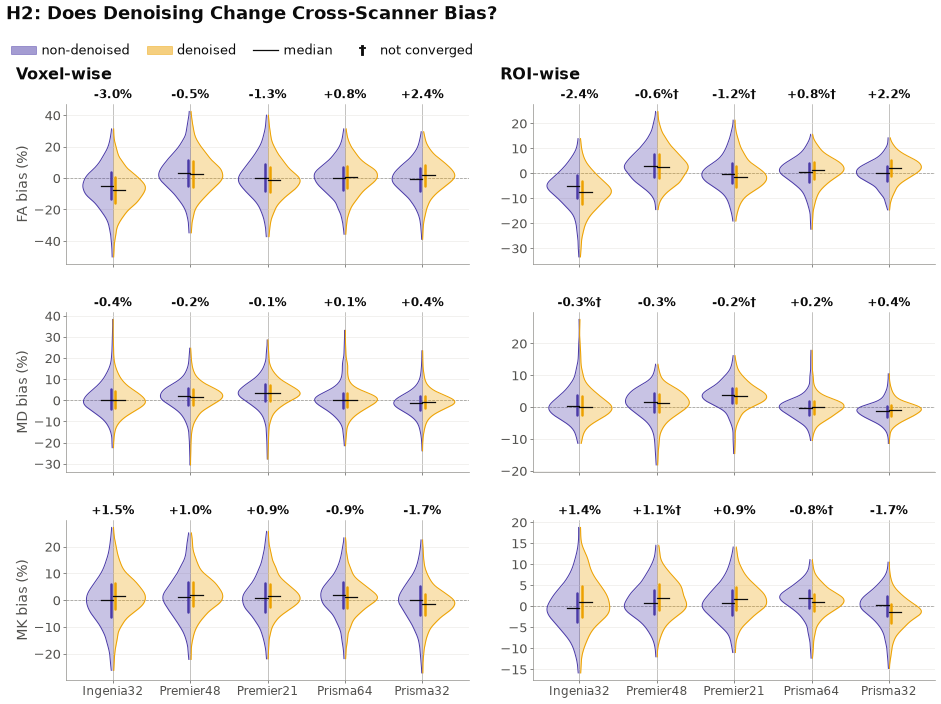

In [4]:
fig = figs.fig_h2(DERIV, METRICS, fs=16)
figs.save(fig, FIGS, "Fig3_H2")
plt.show()

## Exploratory results

In [5]:
pair_fit, pair_res = figs.pair_cnr_fit(DERIV)
display(pair_fit.round(3))
pair_res.pivot_table(index=["repeat_scanner"], columns=["metric", "level"], values="residual_pct").round(2)

,metric,level,pairs,r2,slope_pct_per_unit,dbias_at_equal_qc
0,FA,voxel,5,0.859,5.539,-0.224
1,FA,ROI,5,0.898,4.926,-0.149
2,MD,voxel,5,0.958,0.851,-0.039
3,MD,ROI,5,0.983,0.874,-0.042
4,MK,voxel,5,0.990,-4.012,0.088
5,MK,ROI,5,0.993,-3.980,0.114


metric                FA          MD          MK      
level                ROI voxel   ROI voxel   ROI voxel
repeat_scanner                                        
Ingenia32_SPMICUP  -0.66 -0.97 -0.01 -0.06 -0.02  0.12
Premier21_OCMR      0.10  0.18  0.05  0.08 -0.06 -0.12
Premier48_SPMICQMC  0.74  1.02 -0.03  0.00  0.05 -0.05
Prisma32_FMRIB      0.28  0.27  0.03  0.03 -0.13 -0.12
Prisma64_OHBA      -0.46 -0.50 -0.04 -0.06  0.16  0.17

In [6]:
shift = pd.read_csv(EXPL / "H1_roi_diag" / "C_scanner_shift.csv")
cnr = figs._qc_col(DERIV, "cnr_b1000")
shift["cnr"] = [cnr[(s, sc)] for s, sc in zip(shift.subject, shift.scanner)]
print("Median shift per scanner (%), ROI-wise:")
display(shift.pivot_table(index="scanner", columns="metric", values="roi_shift_pct_median", aggfunc="median")
        .assign(cnr=shift.groupby("scanner").cnr.median()).sort_values("cnr").round(2))
rows = []
for m, g in shift.groupby("metric"):
    for lvl, col in (("ROI", "roi_shift_pct_median"), ("voxel", "vox_shift_pct_median")):
        cen = g[[col, "cnr"]] - g.groupby("scanner")[[col, "cnr"]].transform("mean")
        per = [spearmanr(h.cnr, h[col])[0] for _, h in g.groupby("scanner")]
        rows.append(dict(metric=m, level=lvl, rho_all=spearmanr(g.cnr, g[col])[0],
                         rho_within_scanner=spearmanr(cen.cnr, cen[col])[0], rho_per_scanner_min=min(per),
                         rho_per_scanner_max=max(per)))
pd.DataFrame(rows).round(2)

Median shift per scanner (%), ROI-wise:


metric,FA,MD,MK,cnr
scanner,,,,
Ingenia32_SPMICUP,-3.75,-0.58,3.75,0.98
Premier21_OCMR,-3.66,-0.60,3.51,1.06
Premier48_SPMICQMC,-2.52,-0.54,3.35,1.13
Achieva32_SPMICUP,-2.66,-0.46,2.65,1.26
Prisma64_OHBA,-2.06,-0.29,1.67,1.45
Prisma32_FMRIB,-1.22,-0.20,1.33,1.84


,metric,level,rho_all,rho_within_scanner,rho_per_scanner_min,rho_per_scanner_max
0,FA,ROI,0.93,0.84,0.72,1.00
1,FA,voxel,0.92,0.86,0.72,0.94
2,MD,ROI,0.91,0.68,0.44,0.82
3,MD,voxel,0.90,0.61,0.50,0.79
4,MK,ROI,-0.95,-0.78,-0.89,-0.59
5,MK,voxel,-0.92,-0.69,-0.87,-0.39


In [7]:
offs = pd.read_csv(EXPL / "H1_spread" / "offsets.csv")
sc = offs.groupby(["level", "metric", "scanner", "arm"]).offset_pct.mean().unstack("arm")
sc["change"] = sc.denoised - sc.nondenoised
display(sc.loc["ROI"].round(2))
summ = sc.groupby(["level", "metric"]).agg(sd_nondenoised=("nondenoised", "std"), sd_denoised=("denoised", "std"))
summ["rho_start_vs_change"] = sc.groupby(["level", "metric"]).apply(
    lambda g: spearmanr(g.nondenoised, g.change)[0], include_groups=False)
summ.round(2)

arm                        denoised  nondenoised  change
metric scanner                                          
FA     Achieva32_SPMICUP       2.26         2.42   -0.16
       Ingenia32_SPMICUP      -6.69        -4.95   -1.73
       Premier21_OCMR          0.72         1.16   -0.44
       Premier48_SPMICQMC      3.26         3.39   -0.13
       Prisma32_FMRIB          1.29        -0.56    1.85
       Prisma64_OHBA          -0.84        -1.46    0.62
MD     Achieva32_SPMICUP      -2.31        -2.30   -0.01
       Ingenia32_SPMICUP       0.28         0.45   -0.17
       Premier21_OCMR          1.58         1.71   -0.13
       Premier48_SPMICQMC      0.89         1.04   -0.15
       Prisma32_FMRIB         -0.28        -0.56    0.27
       Prisma64_OHBA          -0.16        -0.34    0.18
MK     Achieva32_SPMICUP      -0.90        -0.76   -0.14
       Ingenia32_SPMICUP      -0.19        -1.23    1.04
       Premier21_OCMR          0.66        -0.13    0.79
       Premier48_SPMICQMC      1.78         0.99    0.79
       Prisma32_FMRIB         -1.05         0.41   -1.46
       Prisma64_OHBA          -0.30         0.71   -1.02

sd_nondenoised  sd_denoised  rho_start_vs_change
level metric                                                  
ROI   FA                3.02         3.56                 0.14
      MD                1.41         1.33                -0.60
      MK                0.87         1.06                -0.49
voxel FA                3.04         3.66                 0.14
      MD                1.61         1.56                -0.60
      MK                1.19         1.34                -0.14

In [8]:
for level in ("ROI", "voxel"):
    fit, res = figs.cnr_residuals(DERIV, level=level)
    print(f"{level}-wise:")
    display(fit.round(3))
    display(res.groupby(["scanner", "metric"]).residual_pp.mean().unstack().round(2))

ROI-wise:


,metric,level,points,slope_pct_per_cnr,r2_cnr,r2_scanner,r2_cnr_scanner,F_scanner_beyond_cnr,p_descriptive
0,FA,ROI,60,2.919,0.804,0.648,0.859,4.113,0.003
1,MD,ROI,60,0.488,0.767,0.728,0.828,3.728,0.006
2,MK,ROI,60,-2.891,0.814,0.778,0.882,6.093,0.000


metric,FA,MD,MK
scanner,,,
Achieva32_SPMICUP,0.04,0.00,-0.11
Ingenia32_SPMICUP,-0.33,0.03,0.14
Premier21_OCMR,0.02,-0.05,0.07
Premier48_SPMICQMC,0.42,-0.04,0.20
Prisma32_FMRIB,-0.14,-0.02,0.21
Prisma64_OHBA,-0.02,0.07,-0.51


voxel-wise:


,metric,level,points,slope_pct_per_cnr,r2_cnr,r2_scanner,r2_cnr_scanner,F_scanner_beyond_cnr,p_descriptive
0,FA,voxel,60,3.194,0.791,0.643,0.859,5.141,0.001
1,MD,voxel,60,0.447,0.736,0.717,0.811,4.190,0.003
2,MK,voxel,60,-2.028,0.758,0.705,0.817,3.418,0.009


metric,FA,MD,MK
scanner,,,
Achieva32_SPMICUP,0.01,0.01,-0.13
Ingenia32_SPMICUP,-0.43,-0.00,0.06
Premier21_OCMR,0.12,-0.07,0.08
Premier48_SPMICQMC,0.49,0.02,0.16
Prisma32_FMRIB,-0.16,-0.03,0.16
Prisma64_OHBA,-0.03,0.08,-0.33


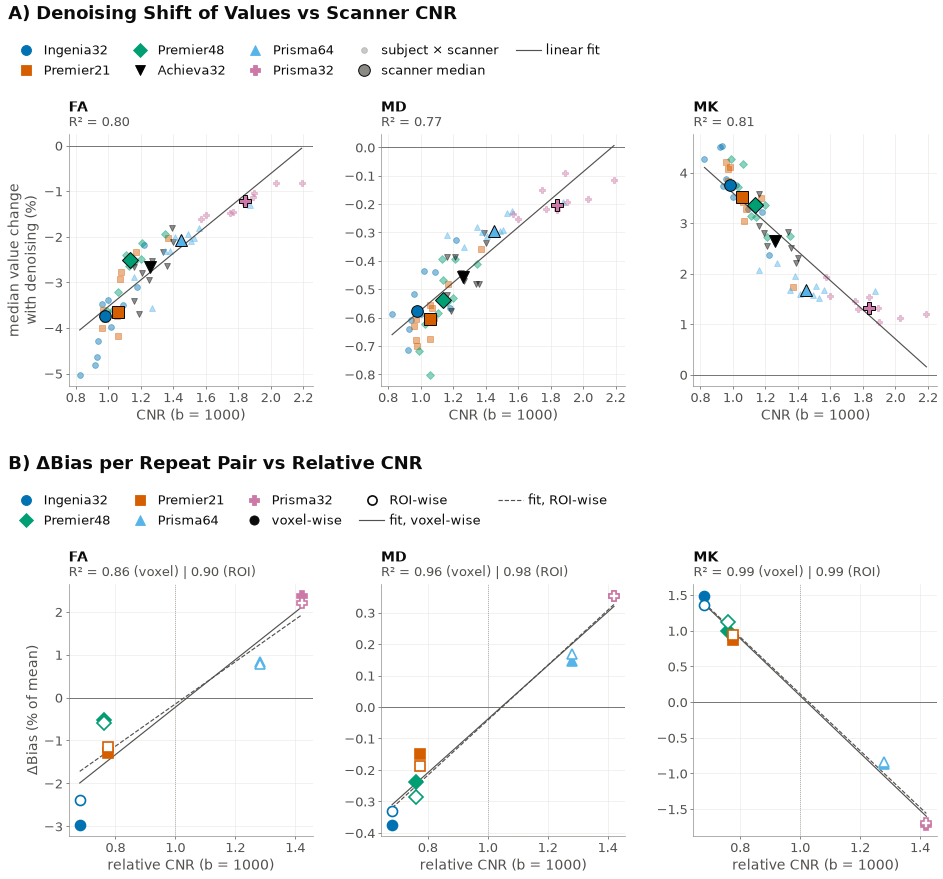

In [9]:
fig = figs.figx_h2(DERIV, METRICS, fs=16)
figs.save(fig, FIGS, "Fig7_H2_exploratory")
plt.show()